# 下載 MNIST 資料
---
首先，匯入 keras 和相關模組。

In [1]:
# 匯入 numpy 和 pandas 模組，numpy 是 python 的程式庫，支援維度陣列與矩陣運算。
# pandas 則提供檔案存取和數據操縱。
import numpy as np
import pandas as pd
# 從 keras.utils 匯入 to_categroical，因為後續要將 label 標籤 轉換成 one-hot encoding。
from tensorflow.keras.utils import to_categorical
# 設定 seed 可以讓每次產生隨機值時，都會有相同的輸出。(若使用GPU，則無法每次皆相同)
seed = 1234
np.random.seed(seed)

Keras 中已經提供許多機器學習常用的數據集，包括波士頓房地產數據、CIFAR10、和這次範例要使用的手寫數據集。所以先從 keras 匯入 MNIST。

第一次執行 mnist.load_data() ，程式會檢查目錄是否已經有檔案，如果沒有就會自動下載，所以第一次可能都會比較久。之後再次執行時不用再次下載就會快速很多。


In [2]:
from tensorflow.keras.datasets import mnist,cifar10
(X_train_image, y_train_label),\
    (X_test_image, y_test_label) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


先來看看 MNIST 資料數據集的筆數，還有訓練資料的組成。

可以看到 train 訓練資料有 60000 筆，test 測試資料有 10000 筆。

訓練資料是由 images 和 labels 所組成共 60000 筆， images 是單色的數字影像，labels 是數字影像對應的真實值。

In [3]:
print('train data : ', len(X_train_image))
print('test data : ', len(X_test_image))

train data :  60000
test data :  10000


In [4]:
print('x_train_image : ', X_train_image.shape)
print('y_train_label : ', y_train_label.shape)

x_train_image :  (60000, 28, 28)
y_train_label :  (60000,)


# 建立 plot_image 函式來顯示數字影像
---
來看看剛剛匯入的手寫數字圖像。



In [5]:
import matplotlib.pyplot as plt
def plot_image(image):
    # 設定圖形顯示大小
    fig = plt.gcf()
    fig.set_size_inches(2, 2)
    # 使用 plt.imshow() 顯示圖像，傳入參數是 28 X 28 的圖形，
    # cmap 參數設定為 binary 以黑白灰階顯示
    plt.imshow(image, cmap = 'binary')
    # 開始繪圖
    plt.show()

傳入訓練集第一筆資料，來看看他的影像。

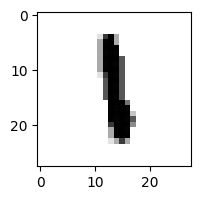

In [6]:
plot_image(X_train_image[200])

看看第一筆資料的 label

In [7]:
y_train_label[200]

np.uint8(1)

# 查看多筆資料 images 與 labels
---
定義 plot_images_labels_prediction() 函式，傳入以下參數：images(數字影像)、labels(對應數字真實值)、prediction(預測結果)、idx(開始顯示影像的index)、num(要顯示的資料筆數，預設是10，不超過25)


In [8]:
def plot_images_labels_prediction(images, labels, prediction,
                                    idx, num = 10):
    # 設定顯示圖形大小
    fig = plt.gcf()
    fig.set_size_inches(12, 14)
    # 如果顯示筆數大於25 則將他設定為25 以避免錯誤
    if num > 25: num = 25
    # 使用 for 迴圈依序畫出 num 個數字圖形
    for i in range(0, num):
        ax = plt.subplot(5, 5, 1+i) # 建立 5 X 5 的 subgraph 子圖形
        ax.imshow(images[idx], cmap = 'binary') # 畫出 subgraph 子圖形
        title = "label=" + str(labels[idx]) # 設定子圖形 title 顯示標籤欄位
        if len(prediction) > 0: # 如果 prediction 有傳入值
            title += ",predict=" + str(prediction[idx]) # 將 prediction 加入 title
        ax.set_title(title, fontsize = 10) # 設定標題大小
        ax.set_xticks([]); ax.set_yticks([]) # 設定不顯示刻度
        idx += 1 # 讀取下一筆
    plt.show() # 開始畫圖

顯示訓練資料前 10 筆資料。不過目前還沒有預測結果所以傳入空 list ，由第 0 筆開始顯示至第 9 筆。

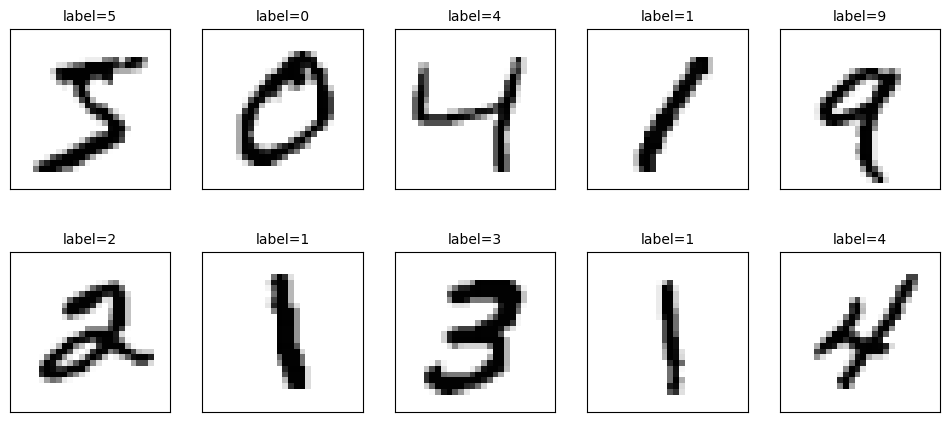

In [9]:
plot_images_labels_prediction(X_train_image, y_train_label, [], 0, 10)

查看 test 測試資料筆數，可以看到共10000筆資料。

In [10]:
print('x_test_image : ', X_test_image.shape)
print('y_test_label : ', y_test_label.shape)

x_test_image :  (10000, 28, 28)
y_test_label :  (10000,)


顯示測試資料前 10 筆資料圖形。

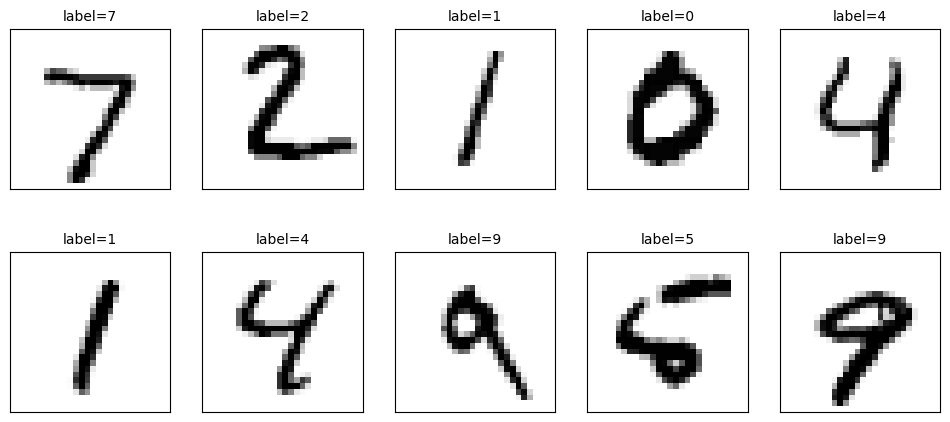

In [11]:
plot_images_labels_prediction(X_test_image, y_test_label, [], 0, 10)

# feature(數字影像的特徵值)資料預處理


In [12]:
X_Train = X_train_image.astype('float32')
X_Test = X_test_image.astype('float32')

將影像資料型態轉換為 float32，後續將在模型中攤平為 784 個特徵值。

In [13]:
print('x_train : ', X_Train.shape)
print('x_test : ', X_Test.shape)

x_train :  (60000, 28, 28)
x_test :  (10000, 28, 28)


將 image 的數字標準化。

因為圖像的數字是介於 0 到 255，所以最簡單的方法就是除以 255。

In [14]:
X_Train_normalize = X_Train / 255
X_Test_normalize = X_Test / 255
# [修改] 增加通道維度 (N,28,28) -> (N,28,28,1)，讓卷積層 Conv2D 可以使用
X_Train_normalize = X_Train_normalize.reshape(-1, 28, 28, 1)
X_Test_normalize = X_Test_normalize.reshape(-1, 28, 28, 1)

# labels(數字影像對應真實值)資料預處理
---
先來查看一下訓練資料 label 標籤欄位前五筆資料，可以看到這是 0 ~ 9 的單一數字。

In [15]:
y_train_label[:5]

array([5, 0, 4, 1, 9], dtype=uint8)

使用我們開頭匯入的 to_categorical函式，傳入 label 標籤，將他們轉換成 one-hot encoding。

In [16]:
y_TrainOneHot = to_categorical(y_train_label)
y_TestOneHot = to_categorical(y_test_label)

查看轉換過後的結果。

In [17]:
y_TrainOneHot[:5]

array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]])

# 建立改良模型 (CNN)
---
**[修改]** 原本的 MLP（Flatten → Dense 32 sigmoid → Dense 10）只能把影像攤平成 784 個數字，無法利用像素之間的空間關係，測試準確率只有約 80%。

這裡改用卷積神經網路 (CNN)：
1. 兩個卷積區塊，每個區塊有兩層 3×3 Conv2D，後接 BatchNormalization 和 ReLU，最後用 MaxPooling 縮小影像、用 Dropout 防止過擬合。
2. 全連接層 Dense 128，後接 BatchNormalization、ReLU 和 Dropout 0.5。
3. 輸出層 Dense 10 + softmax（和原本相同）。

輸入維度仍然是 (28,28,1)，所以匯出的 tflite 可以直接給樹莓派上的 predict.py 使用。

首先先匯入所需要的模組。

In [18]:
from tensorflow.keras import layers, metrics
from tensorflow.keras.layers import (Dense, InputLayer, Flatten, Conv2D, MaxPooling2D,
                                     BatchNormalization, Activation, Dropout)
from tensorflow.keras import models
import tensorflow as tf
tf.random.set_seed(seed)

建立 Sequential 一個線性堆疊模型，後續只要使用 model.add() 將個神經網路層依序加入模型即可。

In [19]:
model = models.Sequential()

建立輸入層
1.   設定輸入層神經元 維度為 (28,28,1)。
2.   **[修改]** 不再直接攤平，先交給卷積層擷取影像特徵。

In [20]:
model.add(InputLayer(shape=(28,28,1)))

**[修改]** 建立卷積區塊與隱藏層。
1.   激活函數由 sigmoid 改為 **ReLU**：sigmoid 在兩端梯度接近 0，訓練很慢；ReLU 收斂快很多。
2.   **BatchNormalization**：把每層輸出重新標準化，讓訓練更穩定、更快收斂。
3.   **MaxPooling2D**：把影像長寬縮小一半，保留最明顯的特徵。
4.   **Dropout**：訓練時隨機關掉部分神經元，降低過擬合。

可以在keras官方文件查看可以使用的Activation function
https://keras.io/zh/activations/

In [21]:
# 卷積區塊 1：32 個 3x3 濾波器 x 2 層
model.add(Conv2D(32, 3, padding='same', use_bias=False))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Conv2D(32, 3, padding='same', use_bias=False))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D())          # 28x28 -> 14x14
model.add(Dropout(0.25))

# 卷積區塊 2：64 個 3x3 濾波器 x 2 層
model.add(Conv2D(64, 3, padding='same', use_bias=False))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Conv2D(64, 3, padding='same', use_bias=False))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D())          # 14x14 -> 7x7
model.add(Dropout(0.25))

# 攤平後接全連接隱藏層
model.add(Flatten())
model.add(Dense(128, use_bias=False))
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Dropout(0.5))

建立輸出層總共 10 個神經元，對應要分類的數字類別 0 ~ 9 。設定激活函數為 softmax ，這樣每一個神經元的輸出結果可視為預測每一個數字的機率。

In [22]:
model.add(Dense(10, activation = 'softmax'))

來看看我們建好的模型的摘要。

In [23]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 468,778 (1.79 MB)

 Trainable params: 468,138 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

None


# 進行訓練
---
首先使用 compile ，對訓練模型進行設定。相關參數有：
1.   loss : 損失函數維持 CategoricalCrossentropy（多類別分類的標準選擇）。
2.   optimizer : **[修改]** 由 sgd 改為 **Adam**，並搭配 **Cosine Decay 學習率排程**：一開始用 0.001 快速學習，之後學習率逐漸降低，讓模型在最後穩定收斂到更好的位置。
3.   metrics : 設定評估模型的方式是 accuracy 準確率。

In [24]:
EPOCHS = 15
BATCH_SIZE = 128
n_train = int(len(X_Train_normalize) * 0.8)            # 80% 訓練、20% 驗證（和原本 validation_split=0.2 相同）
steps_total = int(np.ceil(n_train / BATCH_SIZE)) * EPOCHS

loss_function = 'CategoricalCrossentropy'
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate = 1e-3, decay_steps = steps_total, alpha = 0.01)
optimize_function = tf.keras.optimizers.Adam(learning_rate = lr_schedule)
model.compile(loss = loss_function, optimizer = optimize_function, metrics = ['accuracy'])

開始訓練，過程都會儲存在 train_history 變數。

**[修改] 資料增強 (Data Augmentation)**：每個 batch 送進模型前，隨機把圖片旋轉 (±約 29°，0.08×360°)、平移 (±10%)、縮放 (±10%)。這樣模型看過更多「寫歪、寫偏、寫大寫小」的數字，比較不會死背訓練資料，對樹莓派上用小畫家手寫的數字也更穩定。

資料增強只在訓練時使用，不會放進模型裡，所以匯出的 tflite 不受影響。

1.   驗證資料：和原本 validation_split = 0.2 相同，取最後 20% (12000 筆) 當驗證資料。
2.   epochs = 15，batch_size = 128。
3.   verbose = 2，顯示訓練過程。

使用 GPU（執行階段 → 變更執行階段類型 → T4 GPU）大約 1～2 分鐘可以完成；只用 CPU 大約需要 10 分鐘。

In [25]:
x_tr, y_tr = X_Train_normalize[:n_train], y_TrainOneHot[:n_train]
x_val, y_val = X_Train_normalize[n_train:], y_TrainOneHot[n_train:]

augment = tf.keras.Sequential([
    layers.RandomRotation(0.08, fill_mode = 'constant'),
    layers.RandomTranslation(0.1, 0.1, fill_mode = 'constant'),
    layers.RandomZoom(0.1, fill_mode = 'constant'),
])

train_ds = (tf.data.Dataset.from_tensor_slices((x_tr, y_tr))
            .shuffle(n_train, seed = seed)
            .batch(BATCH_SIZE)
            .map(lambda x, y: (augment(x, training = True), y), num_parallel_calls = tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))

train_history = model.fit(train_ds, validation_data = (x_val, y_val),
                          epochs = EPOCHS, verbose = 2)

Epoch 1/15
375/375 - 26s - 69ms/step - accuracy: 0.8397 - loss: 0.5260 - val_accuracy: 0.1018 - val_loss: 5.2938
Epoch 2/15
375/375 - 6s - 15ms/step - accuracy: 0.9439 - loss: 0.1883 - val_accuracy: 0.9706 - val_loss: 0.0957
Epoch 3/15
375/375 - 7s - 20ms/step - accuracy: 0.9594 - loss: 0.1386 - val_accuracy: 0.9821 - val_loss: 0.0583
Epoch 4/15
375/375 - 5s - 15ms/step - accuracy: 0.9650 - loss: 0.1183 - val_accuracy: 0.9861 - val_loss: 0.0471
Epoch 5/15
375/375 - 10s - 27ms/step - accuracy: 0.9706 - loss: 0.1003 - val_accuracy: 0.9789 - val_loss: 0.0690
Epoch 6/15
375/375 - 7s - 19ms/step - accuracy: 0.9735 - loss: 0.0912 - val_accuracy: 0.9910 - val_loss: 0.0310
Epoch 7/15
375/375 - 9s - 23ms/step - accuracy: 0.9758 - loss: 0.0820 - val_accuracy: 0.9910 - val_loss: 0.0299
Epoch 8/15
375/375 - 7s - 17ms/step - accuracy: 0.9776 - loss: 0.0776 - val_accuracy: 0.9910 - val_loss: 0.0312
Epoch 9/15
375/375 - 5s - 14ms/step - accuracy: 0.9787 - loss: 0.0721 - val_accuracy: 0.9902 - val_los

建立函式顯示訓練過程，會將每一個訓練週期的 accuracy 和 loss 以圖表顯示出來。

In [26]:
def show_train_history(train_history, train, validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc = 'upper left')
    plt.show()

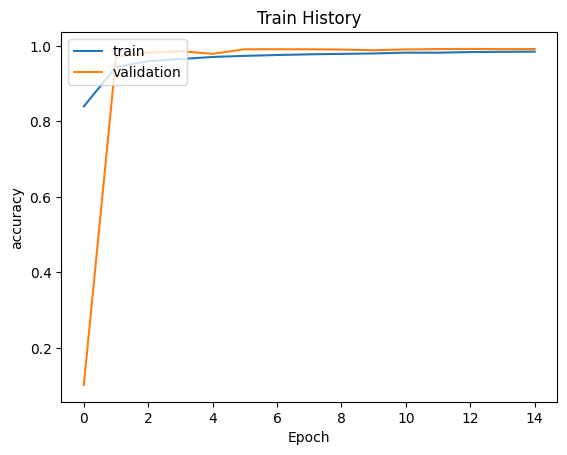

In [27]:
show_train_history(train_history, 'accuracy', 'val_accuracy')

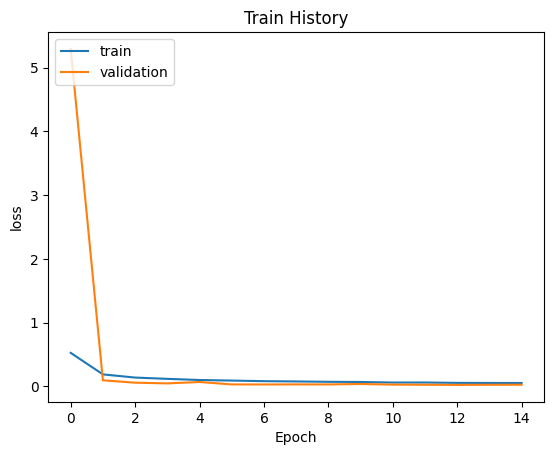

In [28]:
show_train_history(train_history, 'loss', 'val_loss')

# 以測試資料評估模型準確率
---


In [29]:
scores = model.evaluate(X_Test_normalize, y_TestOneHot)
print()
print('accuracy = ', scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.9926 - loss: 0.0228

accuracy =  0.9926000237464905


執行預測，將結果存到 prediction 中。

In [30]:
prediction = np.argmax(model.predict(X_Test_normalize), axis = -1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


In [31]:
prediction

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

顯示 10 筆預測結果。

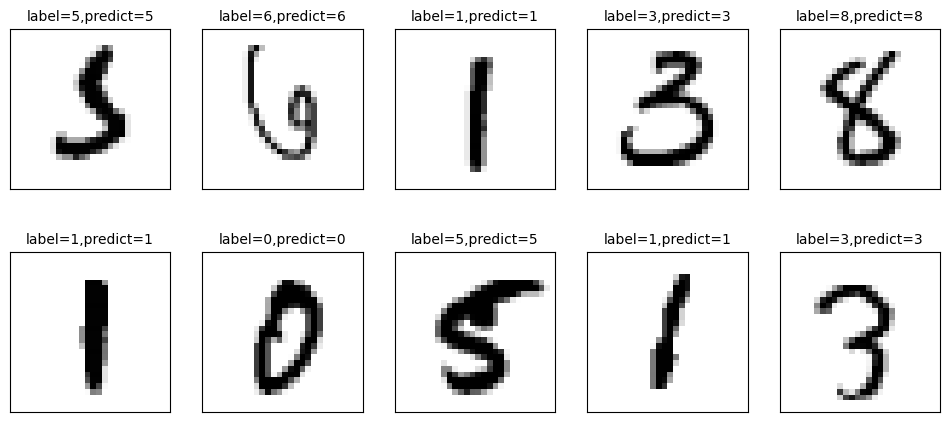

In [32]:
plot_images_labels_prediction(X_test_image, y_test_label, prediction, idx = 340)

In [33]:
y_test_label = y_test_label.reshape(10000)

混淆矩陣

In [34]:
#使用 pandas 中的 crosstab 能夠很方便的建立混淆矩陣。
pd.crosstab(y_test_label, prediction, rownames = ['label'], colnames = ['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,977,0,1,0,0,1,0,1,0,0
1,0,1124,0,2,0,0,1,5,3,0
2,0,0,1027,0,1,0,0,3,1,0
3,0,0,0,1007,0,2,0,0,1,0
4,0,0,0,0,976,0,0,0,3,3
5,0,0,0,5,0,885,2,0,0,0
6,2,3,0,0,2,4,945,0,2,0
7,0,1,9,0,0,0,0,1018,0,0
8,0,1,0,1,1,0,0,0,971,0


In [35]:
import tensorflow as tf

# 載入模型，並建立轉換器
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# 儲存為 tflite 檔案
with open('mnist_model.tflite', 'wb') as f:
    f.write(tflite_model)

# 下載到地端電腦
from google.colab import files
files.download('mnist_model.tflite')

Saved artifact at '/tmp/tmps51937u4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  134051717522512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717524240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717524432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717523856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717523472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717524816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717525392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717525008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717525776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717524624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134051717528080

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>